In [4]:
#Imports
import cv2 #cv2: librería que permite abrir videos, extraer frames y procesar imagenes.
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

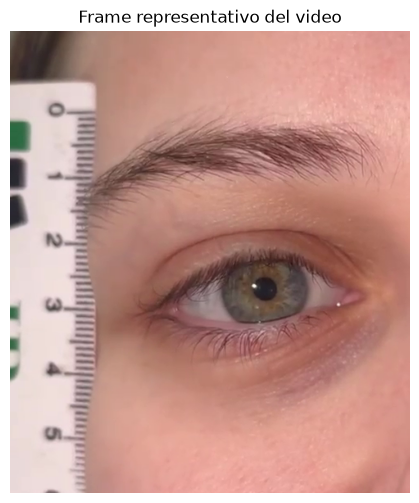

Se cargo la ROI guardada


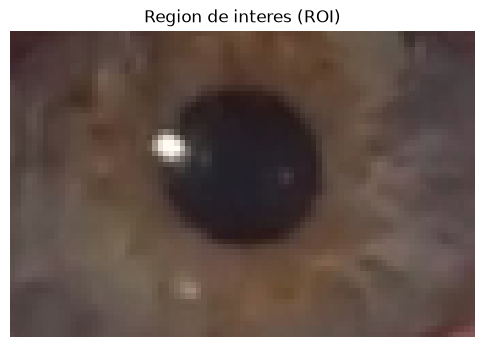

Dimensiones de la ROI:
Ancho: 85 pixeles
Alto: 56 pixeles
Cantidad de canales: 3
Profundidad de bits por canal: 8
Profundidad total por pixel: 24 bits


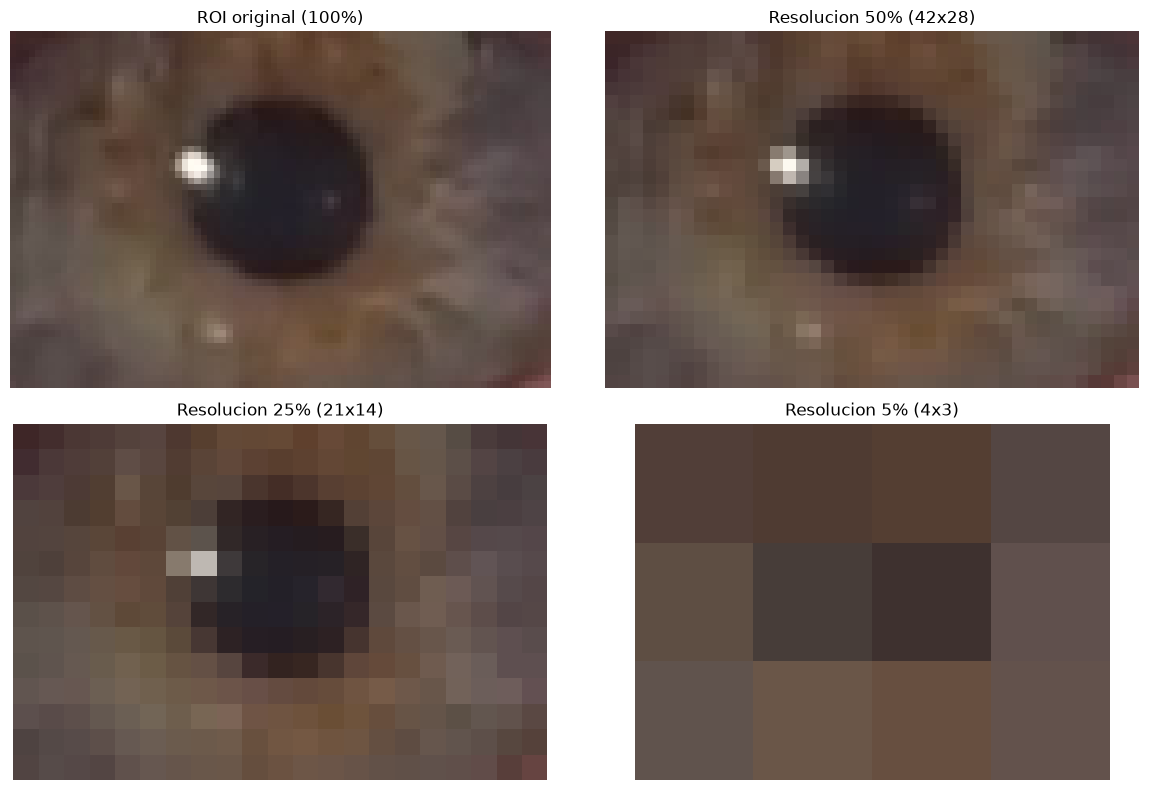

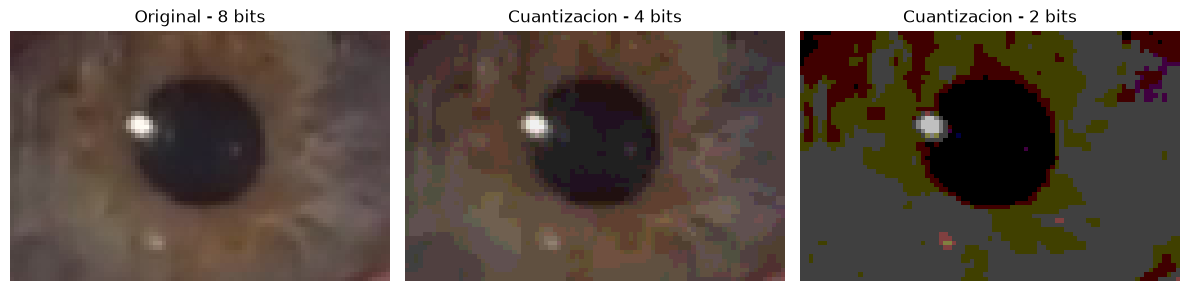

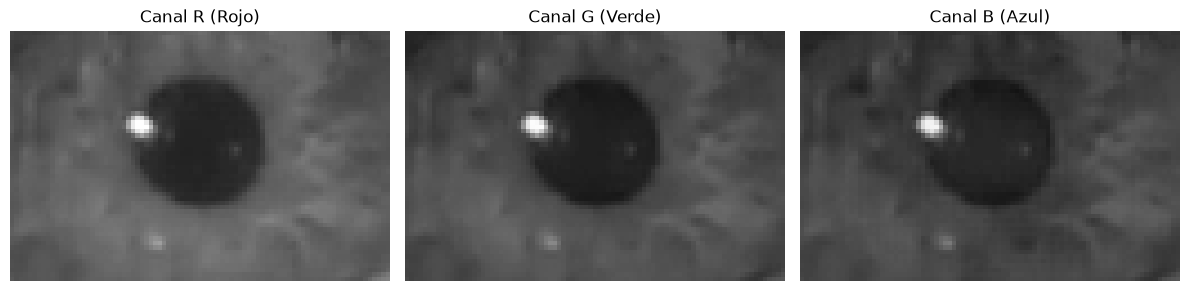

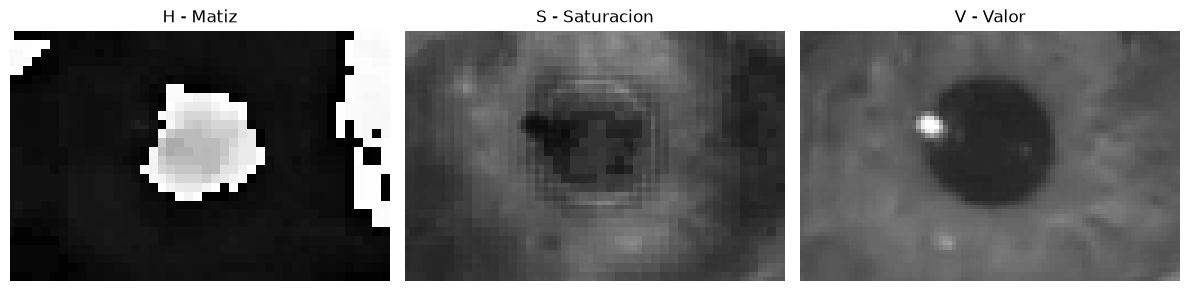

In [5]:
#Módulo 1:  

# Ruta del video
CARPETA_PROYECTO = Path.cwd()
VIDEO_PATH = CARPETA_PROYECTO / "datos" / "Videos_ojo" / "video1.mov"
VIDEO_PATH = CARPETA_PROYECTO / "datos" / "Videos_ojo" / "video1.mov"
#__file__ es la ubicacion del archivo que estamos trabajando, en este caso main.py

# Abrir el video
video = cv2.VideoCapture(str(VIDEO_PATH))

#Si el video no se puede abrir, tira error
if not video.isOpened():
    raise ValueError("No se pudo abrir el video")

#1.1.1

# Obtener la cantidad de frames
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))


# Seleccionar un frame en un instante determinado
segundo = 6

fps = video.get(cv2.CAP_PROP_FPS)
frame_num = int(segundo * fps)

video.set(cv2.CAP_PROP_POS_FRAMES, frame_num)

# Extraer el frame
ret, frame = video.read()
video.release()

if not ret:
    raise ValueError("No se pudo extraer el frame")

# Convertir de BGR (en lo que trabaja opencvs) a RGB para visualizarlo
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Mostrar el frame
plt.figure(figsize=(8, 6))
plt.imshow(frame_rgb)
plt.title("Frame representativo del video")
plt.axis("off")
plt.show()

# Ruta donde se guarda la ROI
ROI_PATH = CARPETA_PROYECTO / "imagenes" / "roi.png"

# Verificar si ya existe una ROI guardada
if ROI_PATH.exists():

    # Si existe, cargarla directamente
    roi = cv2.imread(str(ROI_PATH))
    print("Se cargo la ROI guardada")

else:

    # Si no existe, seleccionar una nueva ROI
    x, y, w, h = cv2.selectROI("Seleccionar ROI", frame, False)
    cv2.destroyAllWindows()

    if w == 0 or h == 0:
        raise ValueError("No se selecciono una ROI")

    roi = frame[y:y+h, x:x+w]

    # Guardar la ROI seleccionada como png en mi compu
    cv2.imwrite(str(ROI_PATH), roi)

# Crear carpeta IMAGENES, donde vamos a guardar el frame y el roi
CARPETA_IMAGENES = CARPETA_PROYECTO / "imagenes"
CARPETA_IMAGENES.mkdir(exist_ok=True)

# Guardar frame completo como png en mi compu
cv2.imwrite(str(CARPETA_IMAGENES / "frame.png"), frame)


# Visualizar ROI
roi_rgb = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(roi_rgb)
plt.title("Region de interes (ROI)")
plt.axis("off")
plt.show()


# 1.1.2 Dimensiones y profundidad de bits

alto, ancho, canales = roi.shape

# Cantidad de bits por canal
bits = roi.dtype.itemsize * 8

print("Dimensiones de la ROI:")
print(f"Ancho: {ancho} pixeles")
print(f"Alto: {alto} pixeles")
print(f"Cantidad de canales: {canales}")
print(f"Profundidad de bits por canal: {bits}")
print(f"Profundidad total por pixel: {bits * canales} bits")


# 1.1.3 Resolucion espacial: submuestreo

escalas = [0.50, 0.25, 0.05]

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(roi_rgb)
plt.title("ROI original (100%)")
plt.axis("off")

for i, escala in enumerate(escalas):
    nuevo_ancho = max(1, round(ancho * escala))
    nuevo_alto = max(1, round(alto * escala))

    roi_reducida = cv2.resize(
        roi_rgb,
        (nuevo_ancho, nuevo_alto),
        interpolation=cv2.INTER_AREA
    )

    plt.subplot(2, 2, i + 2)
    plt.imshow(roi_reducida, interpolation="nearest")
    plt.title(f"Resolucion {int(escala * 100)}% ({nuevo_ancho}x{nuevo_alto})")
    plt.axis("off")

plt.tight_layout()
plt.show()

# 1.1.4 Cuantizacion (profundidad de bits)

# Funcion para reducir la cantidad de niveles de intensidad
def cuantizar(imagen, bits):
    niveles = 2 ** bits
    paso = 256 // niveles

    imagen_cuantizada = (imagen // paso) * paso

    return imagen_cuantizada.astype("uint8")


# Cuantizacion de la ROI a 4 y 2 bits por canal
roi_4bits = cuantizar(roi_rgb, 4)
roi_2bits = cuantizar(roi_rgb, 2)

# Visualizacion comparativa
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(roi_rgb)
plt.title("Original - 8 bits")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(roi_4bits)
plt.title("Cuantizacion - 4 bits")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(roi_2bits)
plt.title("Cuantizacion - 2 bits")
plt.axis("off")

plt.tight_layout()
plt.show()


# 1.1.5 Espacios de color

# A. Separacion de los canales RGB

# Separar la ROI en sus tres canales de color
R, G, B = cv2.split(roi_rgb)

# Visualizar cada canal en escala de grises
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(R, cmap="gray", vmin=0, vmax=255)
plt.title("Canal R (Rojo)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(G, cmap="gray", vmin=0, vmax=255)
plt.title("Canal G (Verde)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(B, cmap="gray", vmin=0, vmax=255)
plt.title("Canal B (Azul)")
plt.axis("off")

plt.tight_layout()
plt.show()


# B. Conversion del espacio RGB a HSV

# Convertir la ROI de RGB a HSV
roi_hsv = cv2.cvtColor(roi_rgb, cv2.COLOR_RGB2HSV)

# Separar las componentes HSV
H, S, V = cv2.split(roi_hsv)

# Visualizar cada componente en escala de grises
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(H, cmap="gray", vmin=0, vmax=179)
plt.title("H - Matiz")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(S, cmap="gray", vmin=0, vmax=255)
plt.title("S - Saturacion")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(V, cmap="gray", vmin=0, vmax=255)
plt.title("V - Valor")
plt.axis("off")

plt.tight_layout()
plt.show()


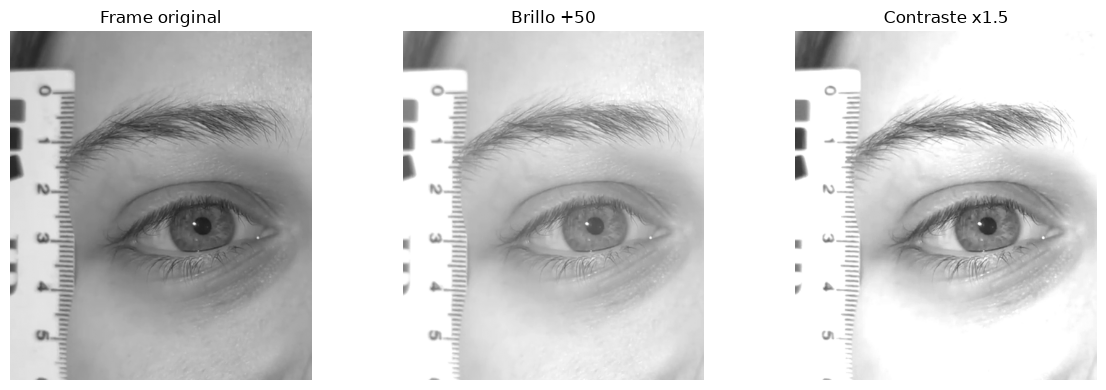

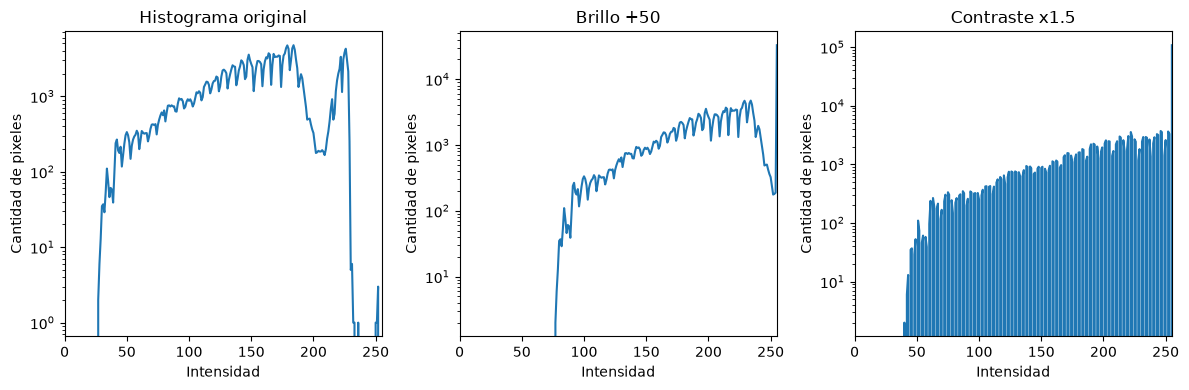

f1 = 34.0
f2 = 98.0


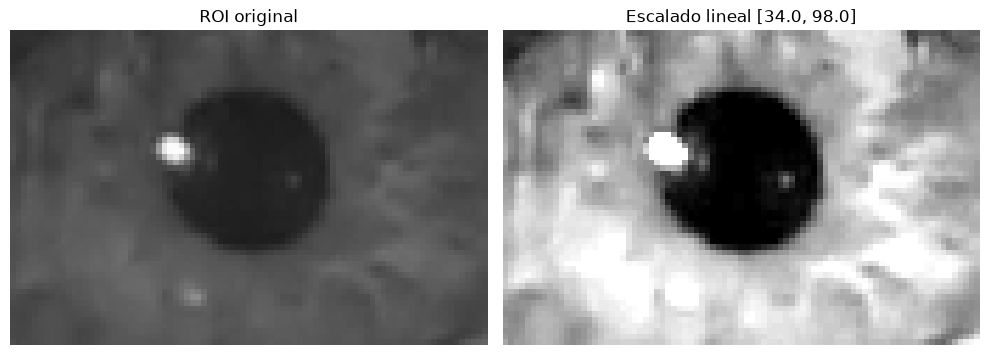

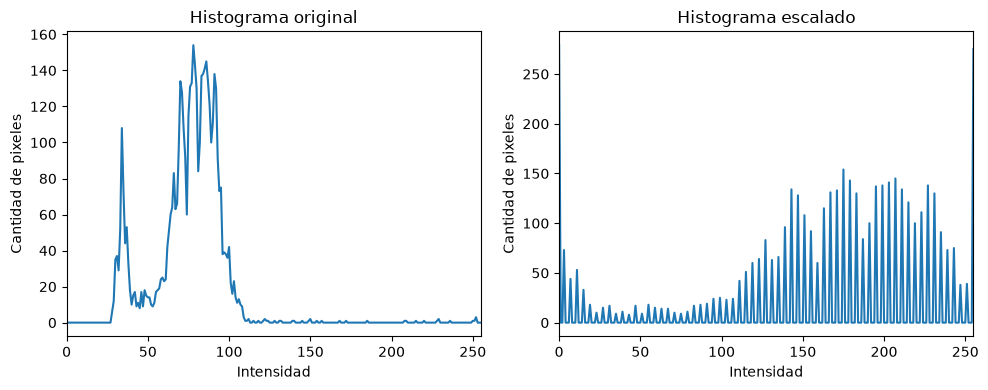

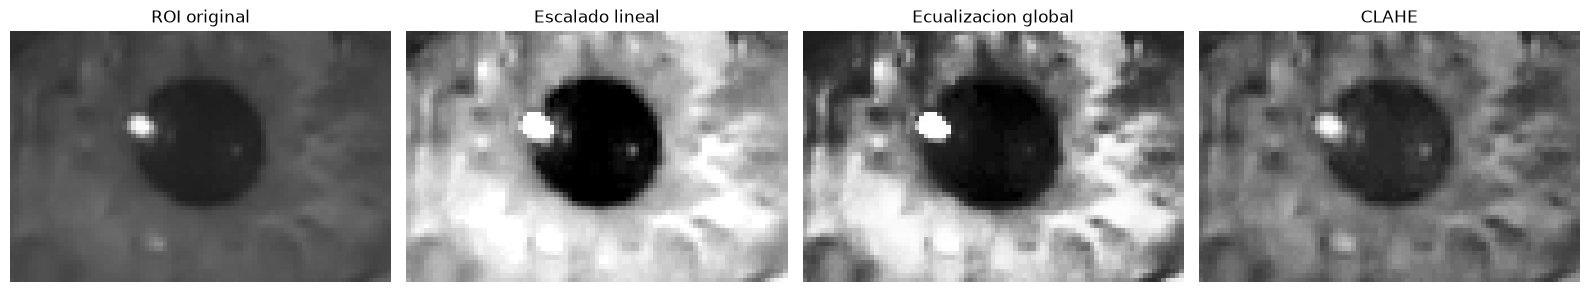

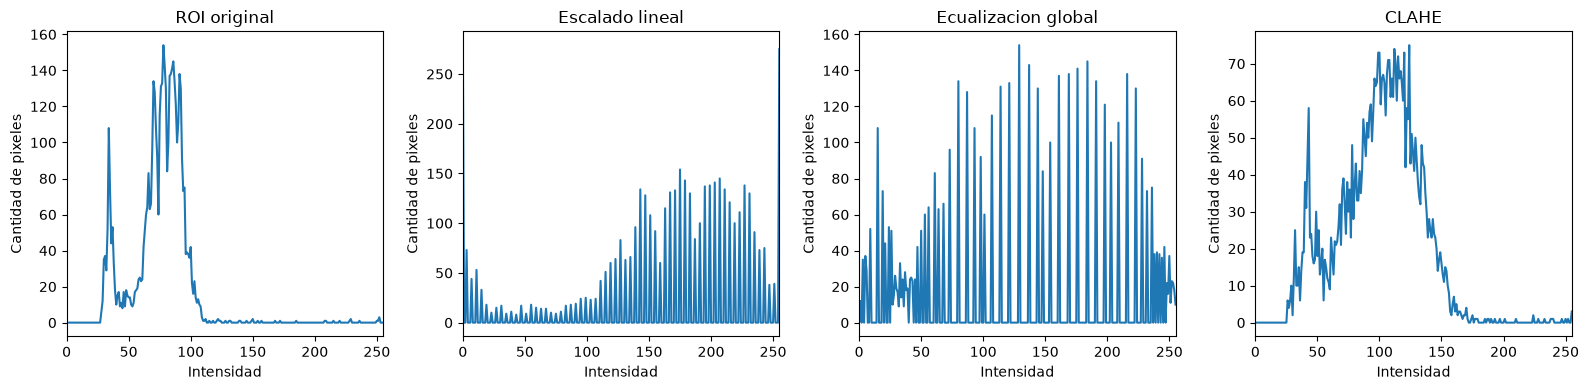

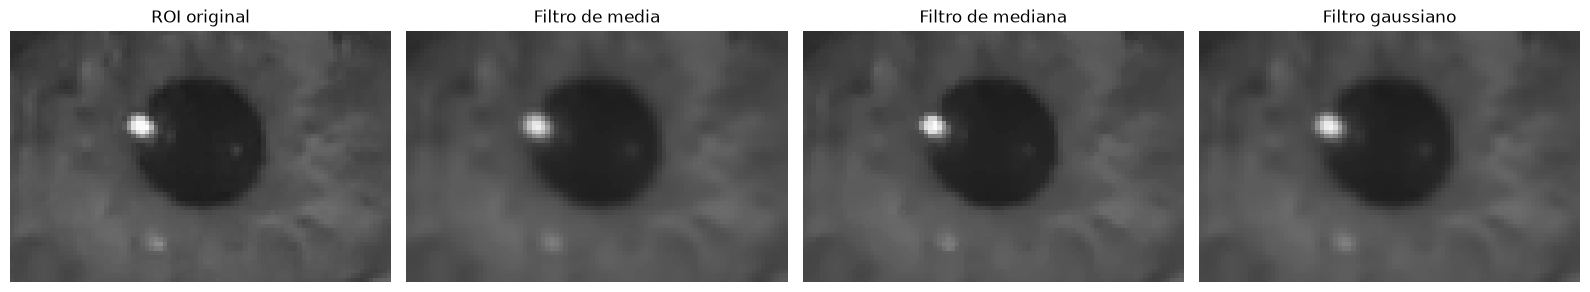

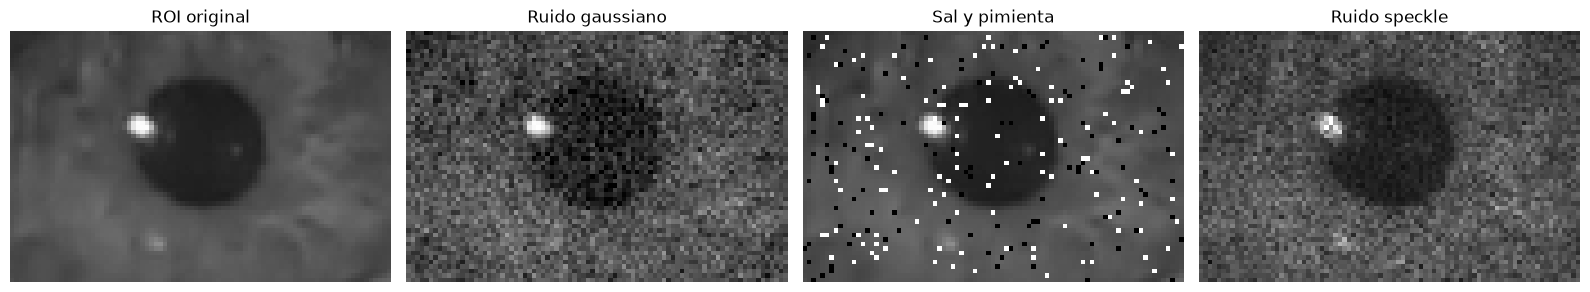

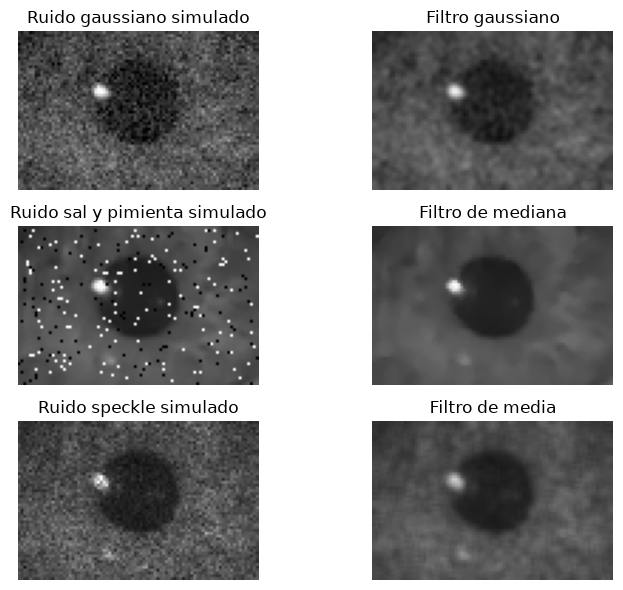

In [6]:
#1.2.1 

# Convertir el frame de BGR a escala de grises
frame_gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

# Aumentar el brillo sumando 50 a cada pixel
# np.clip limita las intensidades al rango [0, 255]
frame_brillo = np.clip(frame_gris.astype(float) + 50, 0, 255).astype("uint8")

# Aumentar el contraste multiplicando por 1.5
frame_contraste = np.clip(frame_gris.astype(float) * 1.5, 0, 255).astype("uint8")

# Visualizar las imagenes
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(frame_gris, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Frame original")

ax[1].imshow(frame_brillo, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Brillo +50")

ax[2].imshow(frame_contraste, cmap="gray", vmin=0, vmax=255)
ax[2].set_title("Contraste x1.5")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Calcular y comparar los histogramas
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

imagenes = [frame_gris, frame_brillo, frame_contraste]
titulos = ["Histograma original", "Brillo +50", "Contraste x1.5"]

for i in range(3):
    histograma = cv2.calcHist([imagenes[i]], [0], None, [256], [0, 256])
    ax[i].plot(histograma)
    ax[i].set_yscale("log") #cambiamos la escala del eje y a logarítmica
    ax[i].set_title(titulos[i])
    ax[i].set_xlabel("Intensidad")
    ax[i].set_ylabel("Cantidad de pixeles")
    ax[i].set_xlim([0, 255])

plt.tight_layout()
plt.show()


# 1.2.2 Escalado por rango de interes
# Convertir la ROI a escala de grises
roi_gris = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

# Definir el intervalo de intensidades de interes
f1 = np.percentile(roi_gris, 5)
f2 = np.percentile(roi_gris, 95)
#Para entender: f1 y f2 representan los límites inferior y superior del intervalo 
# que se desea expandir al rango completo de 0 a 255. Agarramos el 5% y el 95% de 
# de las intensidades de la ROI en escala de grises. De esta manera, el intervalo
# seleccionado contiene aproximadamente el 90% central de los valores de intensidad, 
# excluyendo los extremos de la distribución.

print(f"f1 = {f1:.1f}")
print(f"f2 = {f2:.1f}")

# Aplicar transformacion lineal: las intensidades entre f1 y f2 se expanden al rango 0-255 
#Los valores inferiores a f1 se les asigna 0 y los valores mayores a f2 se les asigna 255
roi_escalada = (roi_gris.astype(float) - f1) * 255 / (f2 - f1)

# Limitar el resultado al rango [0, 255]
roi_escalada = np.clip(roi_escalada, 0, 255).astype("uint8")

# Visualizar las imagenes
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(roi_gris, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("ROI original")

ax[1].imshow(roi_escalada, cmap="gray", vmin=0, vmax=255)
ax[1].set_title(f"Escalado lineal [{f1:.1f}, {f2:.1f}]")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Comparar los histogramas
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

hist_original = cv2.calcHist([roi_gris], [0], None, [256], [0, 256])
hist_escalado = cv2.calcHist([roi_escalada], [0], None, [256], [0, 256])

ax[0].plot(hist_original)
ax[0].set_title("Histograma original")

ax[1].plot(hist_escalado)
ax[1].set_title("Histograma escalado")

for a in ax:
    a.set_xlabel("Intensidad")
    a.set_ylabel("Cantidad de pixeles")
    a.set_xlim([0, 255])

plt.tight_layout()
plt.show()

# 1.2.3 Ecualización del histograma

# Ecualizacion global
roi_ecualizada = cv2.equalizeHist(roi_gris)

# Ecualizacion local (CLAHE)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
roi_clahe = clahe.apply(roi_gris)

# Comparar las imagenes
fig, ax = plt.subplots(1, 4, figsize=(16, 4))

imagenes = [roi_gris, roi_escalada, roi_ecualizada, roi_clahe]
titulos = ["ROI original", "Escalado lineal", "Ecualizacion global", "CLAHE"]

for i in range(4):
    ax[i].imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)
    ax[i].set_title(titulos[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()

# Comparar los histogramas
fig, ax = plt.subplots(1, 4, figsize=(16, 4))

for i in range(4):
    histograma = cv2.calcHist([imagenes[i]], [0], None, [256], [0, 256])

    ax[i].plot(histograma)
    ax[i].set_title(titulos[i])
    ax[i].set_xlabel("Intensidad")
    ax[i].set_ylabel("Cantidad de pixeles")
    ax[i].set_xlim([0, 255])

plt.tight_layout()
plt.show()


# 1.2.4 Analisis de ruido y filtrado espacial

# A. Aplicacion de filtros sobre la ROI original (sin ruido simulado)

# Filtro de media
roi_media = cv2.blur(roi_gris, (3, 3))

# Filtro de mediana
roi_mediana = cv2.medianBlur(roi_gris, 3)

# Filtro gaussiano
roi_filtro_gaussiano = cv2.GaussianBlur(roi_gris, (3, 3), 0)

# Comparar la imagen original con las tres filtradas
imagenes = [roi_gris, roi_media, roi_mediana, roi_filtro_gaussiano]
titulos = ["ROI original", "Filtro de media", "Filtro de mediana", "Filtro gaussiano"]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

for i in range(4):
    ax[i].imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)
    ax[i].set_title(titulos[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()


# B. Simulacion de los distintos tipos de ruido

# Creamos un generador de numeros aleatorios
rng = np.random.default_rng(42)

# Matriz de gaussiano
ruido_gaussiano = rng.normal(0, 20, roi_gris.shape)

#Sumamos el ruido gaussiano a las intensidades originales
roi_gaussiana = np.clip(
    roi_gris.astype(float) + ruido_gaussiano, 0, 255
).astype("uint8")

# Ruido sal y pimienta
roi_sal_pimienta = roi_gris.copy()

#Seleccionamos aleatoriamente qué pixeles vamos a modificar para el ruido sal y pimienta
probabilidad = 0.05 #queremos modificar el 5% de los pixeles de la imagen
aleatorios = rng.random(roi_gris.shape) #generamos numeros aleatorios

roi_sal_pimienta[aleatorios < probabilidad / 2] = 0
roi_sal_pimienta[(aleatorios >= probabilidad / 2) &
                 (aleatorios < probabilidad)] = 255

# Ruido speckle
ruido_speckle = rng.normal(0, 0.2, roi_gris.shape)
roi_speckle = np.clip(
    roi_gris.astype(float) * (1 + ruido_speckle), 0, 255
).astype("uint8")

# Comparacion de los ruidos
imagenes_ruido = [
    roi_gris,
    roi_gaussiana,
    roi_sal_pimienta,
    roi_speckle
]

titulos_ruido = [
    "ROI original",
    "Ruido gaussiano",
    "Sal y pimienta",
    "Ruido speckle"
]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

for i in range(4):
    ax[i].imshow(imagenes_ruido[i], cmap="gray", vmin=0, vmax=255)
    ax[i].set_title(titulos_ruido[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()


# C. Aplicacion de filtros espaciales

# Aplicar filtro gaussiano al ruido gaussiano
roi_gaussiana_filtrada = cv2.GaussianBlur(roi_gaussiana, (3, 3), 0)

# Aplicar filtro de mediana al ruido sal y pimienta
roi_sal_pimienta_filtrada = cv2.medianBlur(roi_sal_pimienta, 3)

# Aplicar filtro de media al ruido speckle
roi_speckle_filtrada = cv2.blur(roi_speckle, (3, 3))

# Comparar imagenes antes y despues del filtrado
imagenes = [
    roi_gaussiana,
    roi_gaussiana_filtrada,
    roi_sal_pimienta,
    roi_sal_pimienta_filtrada,
    roi_speckle,
    roi_speckle_filtrada
]

titulos = [
    "Ruido gaussiano simulado",
    "Filtro gaussiano",
    "Ruido sal y pimienta simulado",
    "Filtro de mediana",
    "Ruido speckle simulado",
    "Filtro de media"
]

fig, ax = plt.subplots(3, 2, figsize=(8, 6))

for i in range(3):
    for j in range(2):
        ax[i, j].imshow(imagenes[i*2+j], cmap="gray", vmin=0, vmax=255)
        ax[i, j].set_title(titulos[i*2+j])
        ax[i, j].axis("off")

plt.tight_layout()
plt.show()


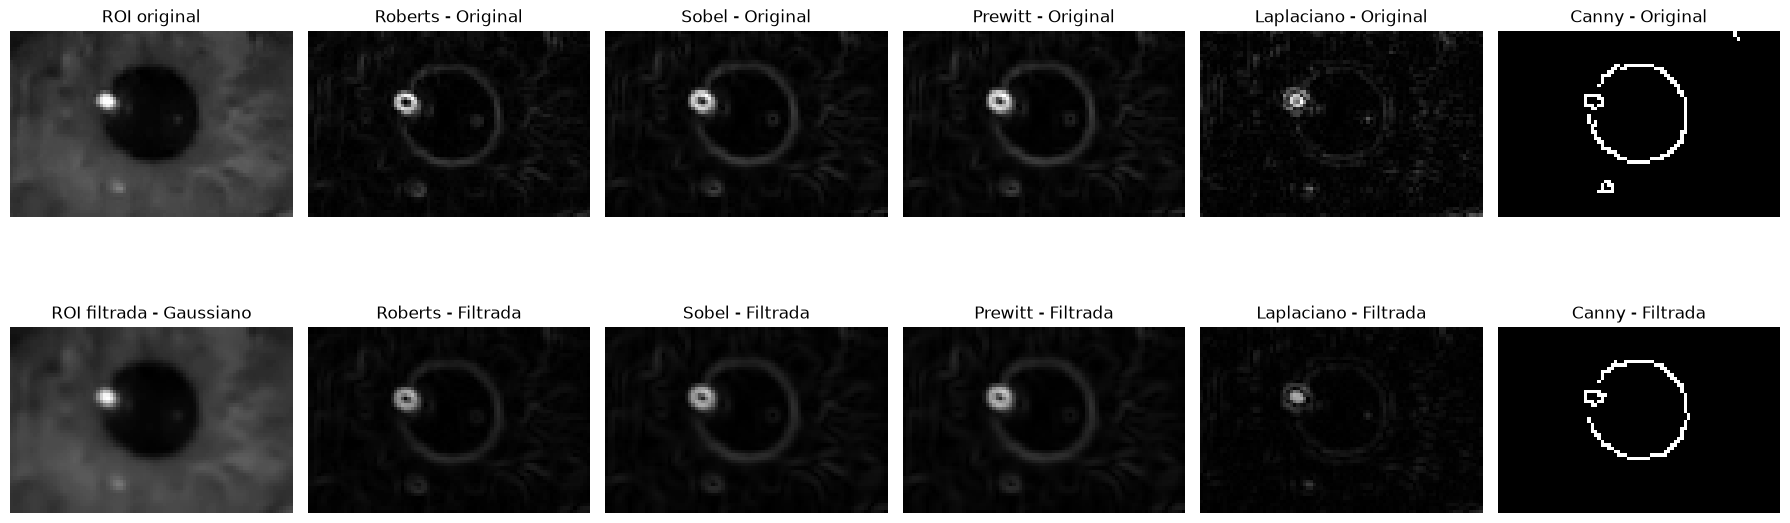

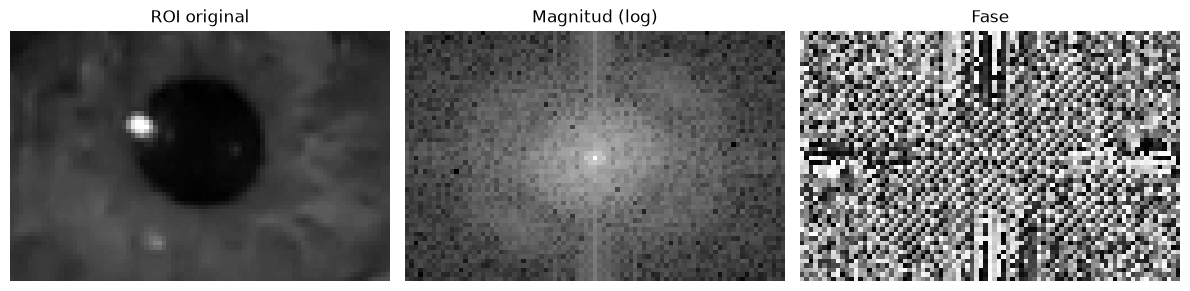

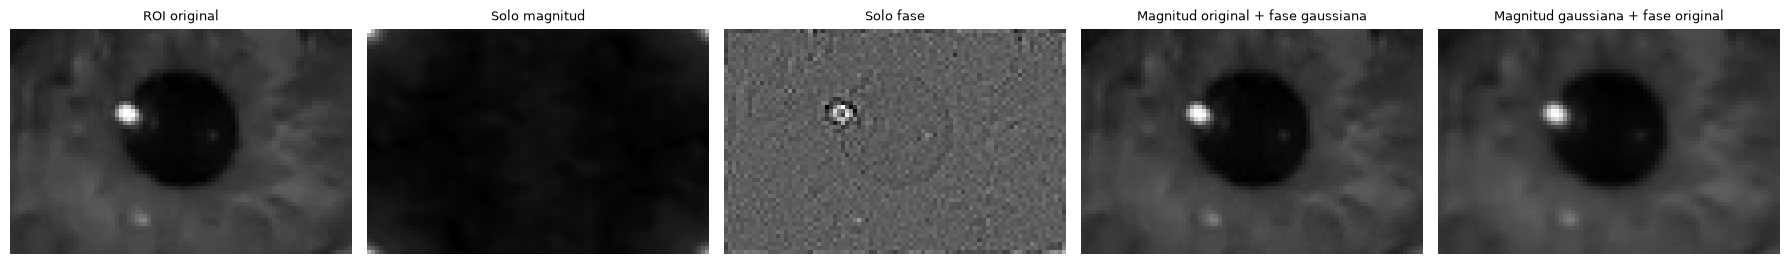

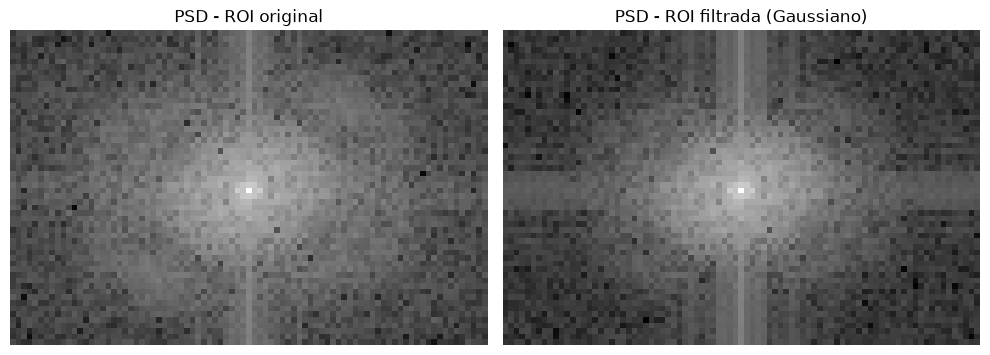

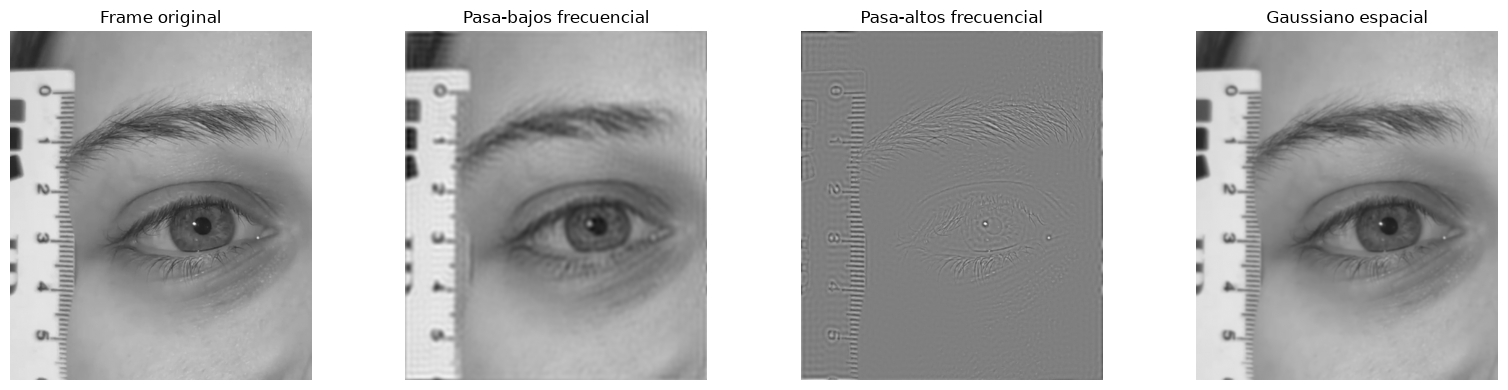

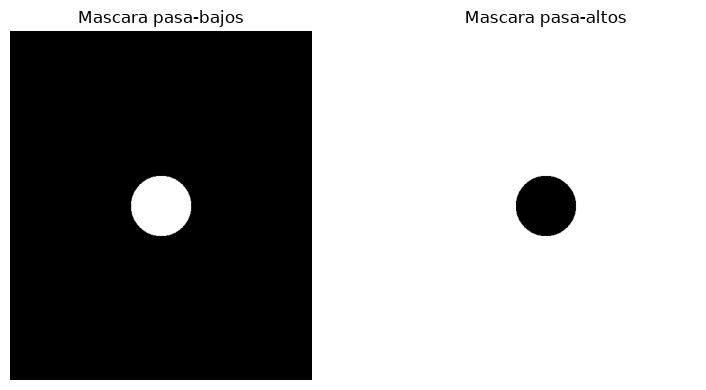


--- Comparacion PSNR y SSIM ---

Filtro: Media
PSNR: 39.57 dB
SSIM: 0.9769

Filtro: Mediana
PSNR: 42.42 dB
SSIM: 0.9834

Filtro: Gaussiano
PSNR: 41.75 dB
SSIM: 0.9858


In [7]:
# 1.3 Deteccion de bordes y dominio frecuencial

# 1.3.1 Deteccion de bordes

# Imagen original y filtrada en el punto 1.2.4
imagen_original = roi_gris
imagen_filtrada = roi_filtro_gaussiano

# Funcion para aplicar los cinco operadores
def detectar_bordes(imagen):

    imagen_float = imagen.astype(np.float32)

    # Roberts
    kernel_roberts_x = np.array([[1, 0],
                                 [0, -1]], dtype=np.float32)

    kernel_roberts_y = np.array([[0, 1],
                                 [-1, 0]], dtype=np.float32)

    roberts_x = cv2.filter2D(
        imagen_float, cv2.CV_32F, kernel_roberts_x
    )
    roberts_y = cv2.filter2D(
        imagen_float, cv2.CV_32F, kernel_roberts_y
    )

    roberts = cv2.magnitude(roberts_x, roberts_y)

    # Sobel
    sobel_x = cv2.Sobel(imagen, cv2.CV_32F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(imagen, cv2.CV_32F, 0, 1, ksize=3)

    sobel = cv2.magnitude(sobel_x, sobel_y)

    # Prewitt
    kernel_prewitt_x = np.array([[-1, 0, 1],
                                 [-1, 0, 1],
                                 [-1, 0, 1]], dtype=np.float32)

    kernel_prewitt_y = np.array([[-1, -1, -1],
                                 [0, 0, 0],
                                 [1, 1, 1]], dtype=np.float32)

    prewitt_x = cv2.filter2D(
        imagen_float, cv2.CV_32F, kernel_prewitt_x
    )
    prewitt_y = cv2.filter2D(
        imagen_float, cv2.CV_32F, kernel_prewitt_y
    )

    prewitt = cv2.magnitude(prewitt_x, prewitt_y)

    # Laplaciano
    laplaciano = cv2.Laplacian(
        imagen, cv2.CV_32F, ksize=3
    )
    laplaciano = np.abs(laplaciano)

    # Canny
    canny = cv2.Canny(imagen, 50, 150)

    return [roberts, sobel, prewitt, laplaciano, canny]


# Aplicar los operadores a ambas imagenes
bordes_original = detectar_bordes(imagen_original)
bordes_filtrada = detectar_bordes(imagen_filtrada)

nombres = ["Roberts", "Sobel", "Prewitt",
           "Laplaciano", "Canny"]

# Comparacion visual
fig, ax = plt.subplots(2, 6, figsize=(18, 7))

ax[0, 0].imshow(imagen_original, cmap="gray")
ax[0, 0].set_title("ROI original")

ax[1, 0].imshow(imagen_filtrada, cmap="gray")
ax[1, 0].set_title("ROI filtrada - Gaussiano")

for i in range(5):

    # Usamos la misma escala por operador
    # para comparar original y filtrada
    limite = max(
        np.max(bordes_original[i]),
        np.max(bordes_filtrada[i]),
        1
    )

    ax[0, i+1].imshow(
        bordes_original[i], cmap="gray",
        vmin=0, vmax=limite
    )
    ax[0, i+1].set_title(nombres[i] + " - Original")

    ax[1, i+1].imshow(
        bordes_filtrada[i], cmap="gray",
        vmin=0, vmax=limite
    )
    ax[1, i+1].set_title(nombres[i] + " - Filtrada")

for fila in ax:
    for a in fila:
        a.axis("off")

plt.tight_layout()
plt.show()


# 1.3.2 Transformada de Fourier 2D

# Calcular la transformada de Fourier de la ROI original
F_original = np.fft.fft2(roi_gris)

# Centrar las frecuencias bajas
F_original_centrada = np.fft.fftshift(F_original)

# Obtener magnitud y fase
magnitud_original = np.abs(F_original_centrada)
fase_original = np.angle(F_original_centrada)

# Representar la magnitud en escala logaritmica
magnitud_log = np.log1p(magnitud_original)

# Visualizar la imagen, magnitud y fase
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(roi_gris, cmap="gray")
ax[0].set_title("ROI original")

ax[1].imshow(magnitud_log, cmap="gray")
ax[1].set_title("Magnitud (log)")

ax[2].imshow(fase_original, cmap="gray",
             vmin=-np.pi, vmax=np.pi)
ax[2].set_title("Fase")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# A. Reconstruccion utilizando solo magnitud

# Conservar magnitud y establecer fase igual a cero
F_solo_magnitud = magnitud_original

recon_magnitud = np.fft.ifft2(
    np.fft.ifftshift(F_solo_magnitud)
).real


# B. Reconstruccion utilizando solo fase

# Conservar fase y establecer magnitud igual a uno
F_solo_fase = np.exp(1j * fase_original)

recon_fase = np.fft.ifft2(
    np.fft.ifftshift(F_solo_fase)
).real


# C. Cruzar magnitud y fase de dos imagenes

# Fourier de la ROI filtrada con gaussiano
F_gaussiana = np.fft.fftshift(
    np.fft.fft2(roi_filtro_gaussiano)
)

magnitud_gaussiana = np.abs(F_gaussiana)
fase_gaussiana = np.angle(F_gaussiana)

# Magnitud original + fase gaussiana
F_cruzada_1 = magnitud_original * np.exp(
    1j * fase_gaussiana
)

recon_cruzada_1 = np.fft.ifft2(
    np.fft.ifftshift(F_cruzada_1)
).real

# Magnitud gaussiana + fase original
F_cruzada_2 = magnitud_gaussiana * np.exp(
    1j * fase_original
)

recon_cruzada_2 = np.fft.ifft2(
    np.fft.ifftshift(F_cruzada_2)
).real


# D. Visualizacion comparativa

# Normalizar cada reconstruccion para visualizarla
def normalizar_imagen(imagen):
    return cv2.normalize(
        imagen.astype(np.float32),
        None, 0, 255, cv2.NORM_MINMAX
    )

imagenes = [
    roi_gris,
    recon_magnitud,
    recon_fase,
    recon_cruzada_1,
    recon_cruzada_2
]

titulos = [
    "ROI original",
    "Solo magnitud",
    "Solo fase",
    "Magnitud original + fase gaussiana",
    "Magnitud gaussiana + fase original"
]

fig, ax = plt.subplots(1, 5, figsize=(18, 4))

for i in range(5):
    ax[i].imshow(
        normalizar_imagen(imagenes[i]),
        cmap="gray"
    )
    ax[i].set_title(titulos[i], fontsize=9)
    ax[i].axis("off")

plt.tight_layout()
plt.show()


# 1.3.3 Densidad espectral de potencia (PSD)

# Calcular la transformada de Fourier de la ROI original y filtrada
F_original_psd = np.fft.fftshift(
    np.fft.fft2(roi_gris.astype(float))
)

F_gaussiana_psd = np.fft.fftshift(
    np.fft.fft2(roi_filtro_gaussiano.astype(float))
)

# Calcular la PSD como el cuadrado de la magnitud
psd_original = np.abs(F_original_psd)**2
psd_gaussiana = np.abs(F_gaussiana_psd)**2

# Aplicar escala logaritmica para visualizar mejor
psd_original_log = np.log1p(psd_original)
psd_gaussiana_log = np.log1p(psd_gaussiana)

# Usar la misma escala para comparar las dos imagenes
escala_maxima = max(
    np.max(psd_original_log),
    np.max(psd_gaussiana_log)
)

# Visualizar las PSD
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(
    psd_original_log,
    cmap="gray",
    vmin=0,
    vmax=escala_maxima
)
ax[0].set_title("PSD - ROI original")

ax[1].imshow(
    psd_gaussiana_log,
    cmap="gray",
    vmin=0,
    vmax=escala_maxima
)
ax[1].set_title("PSD - ROI filtrada (Gaussiano)")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# 1.3.4 Filtrado en el dominio frecuencial

# Calcular la transformada de Fourier del frame completo
F_frame = np.fft.fft2(frame_gris.astype(float))

# Centrar las frecuencias bajas
F_frame_centrada = np.fft.fftshift(F_frame)

# Obtener las dimensiones del frame
alto_frame, ancho_frame = frame_gris.shape

# Crear coordenadas para calcular la distancia al centro
Y, X = np.ogrid[:alto_frame, :ancho_frame]

centro_y = alto_frame // 2
centro_x = ancho_frame // 2

distancia = np.sqrt(
    (X - centro_x)**2 + (Y - centro_y)**2
)

# Definir una frecuencia de corte inicial
D0 = 0.10 * min(alto_frame, ancho_frame)

# Crear las mascaras de filtrado
# Pasa-bajos: conserva frecuencias cercanas al centro
H_pasabajos = (distancia <= D0).astype(float)

# Pasa-altos: conserva frecuencias alejadas del centro
H_pasaaltos = (distancia > D0).astype(float)

# Aplicar las mascaras en el dominio frecuencial
F_pasabajos = F_frame_centrada * H_pasabajos
F_pasaaltos = F_frame_centrada * H_pasaaltos

# Reconstruir las imagenes mediante transformada inversa
frame_pasabajos = np.fft.ifft2(
    np.fft.ifftshift(F_pasabajos)
).real

frame_pasaaltos = np.fft.ifft2(
    np.fft.ifftshift(F_pasaaltos)
).real

# Aplicar filtro gaussiano en el dominio espacial
# para comparar ambos tipos de filtrado
frame_gaussiano = cv2.GaussianBlur(
    frame_gris, (5, 5), 0
)

# Visualizar las imagenes
fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(frame_gris, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Frame original")

ax[1].imshow(frame_pasabajos, cmap="gray",
             vmin=0, vmax=255)
ax[1].set_title("Pasa-bajos frecuencial")

# El pasa-altos puede contener valores negativos.
# Centramos la visualizacion en cero para observar bordes.
limite = max(np.max(np.abs(frame_pasaaltos)), 1)

ax[2].imshow(frame_pasaaltos, cmap="gray",
             vmin=-limite, vmax=limite)
ax[2].set_title("Pasa-altos frecuencial")

ax[3].imshow(frame_gaussiano, cmap="gray",
             vmin=0, vmax=255)
ax[3].set_title("Gaussiano espacial")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# Visualizar las mascaras frecuenciales
fig, ax = plt.subplots(1, 2, figsize=(8, 4))

ax[0].imshow(H_pasabajos, cmap="gray")
ax[0].set_title("Mascara pasa-bajos")

ax[1].imshow(H_pasaaltos, cmap="gray")
ax[1].set_title("Mascara pasa-altos")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Preguntas finales del 1.3 - PSNR y SSIM

from skimage.metrics import structural_similarity as ssim

# Imagen de referencia: ROI original
imagen_referencia = roi_gris

# Imagenes obtenidas con los filtros espaciales del 1.2.4
imagenes_filtradas = {
    "Media": roi_media,
    "Mediana": roi_mediana,
    "Gaussiano": roi_filtro_gaussiano
}

# Calcular PSNR y SSIM para cada filtro
print("\n--- Comparacion PSNR y SSIM ---")

for nombre, imagen in imagenes_filtradas.items():

    # PSNR: compara las diferencias de intensidad
    psnr_valor = cv2.PSNR(imagen_referencia, imagen)

    # SSIM: compara la similitud estructural
    ssim_valor = ssim(
        imagen_referencia,
        imagen,
        data_range=255
    )

    print(f"\nFiltro: {nombre}")
    print(f"PSNR: {psnr_valor:.2f} dB")
    print(f"SSIM: {ssim_valor:.4f}")




Umbral calculado por Otsu: 62.0


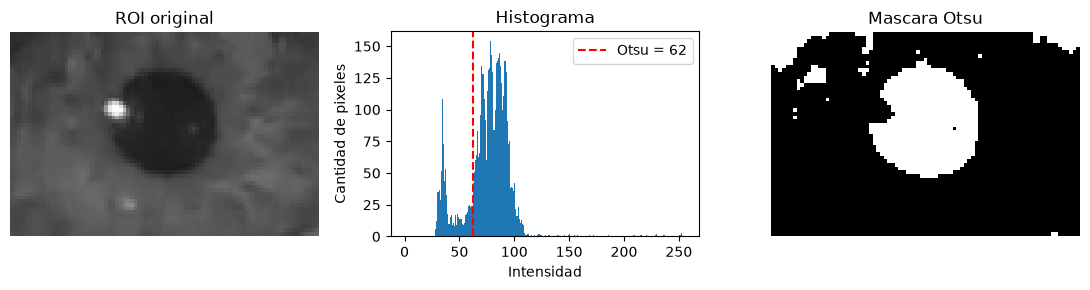

K=2 - Centroides: [41.32736 82.35177]
K=3 - Centroides: [37.63319 71.92142 91.49194]
K=4 - Centroides: [ 37.63319  71.54069  89.98051 214.83333]
K=5 - Centroides: [ 37.155922  67.24404   81.53876   95.088234 222.25    ]


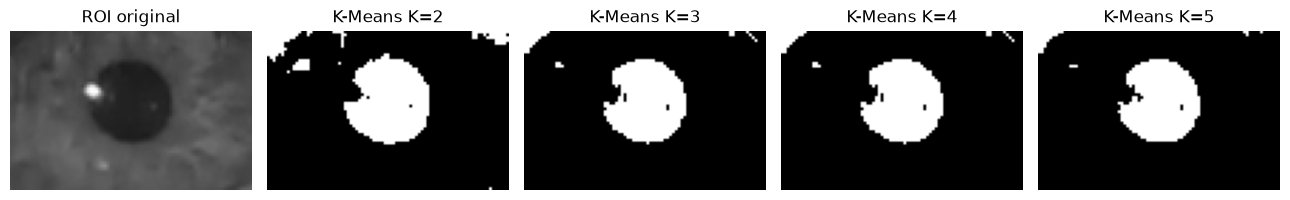

/var/folders/g4/f7c0cm4s4jdb5hpjg_lfmx7r0000gn/T/ipykernel_43194/265821537.py:131: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  puntos = plt.ginput(2, timeout=0)


In [ ]:
# MODULO 2: Segmentacion y morfologia matematica de la pupila

from skimage.segmentation import active_contour, watershed
from skimage.filters import sobel


# 2.1 Algoritmos de segmentacion

# Trabajamos sobre una copia de la ROI original en escala de grises
# No aplicamos ningun filtro adicional
imagen_segmentacion = roi_gris.copy()


# 2.1.1 Umbralizacion automatica de Otsu

umbral_otsu, mascara_otsu = cv2.threshold(
    imagen_segmentacion,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

print(f"Umbral calculado por Otsu: {umbral_otsu}")

# Comparar la ROI, el histograma y la mascara
fig, ax = plt.subplots(1, 3, figsize=(11, 3))

ax[0].imshow(imagen_segmentacion, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("ROI original")
ax[0].axis("off")

ax[1].hist(imagen_segmentacion.ravel(), bins=256, range=(0, 256))
ax[1].axvline(
    umbral_otsu,
    color="red",
    linestyle="--",
    label=f"Otsu = {umbral_otsu:.0f}"
)
ax[1].set_title("Histograma")
ax[1].set_xlabel("Intensidad")
ax[1].set_ylabel("Cantidad de pixeles")
ax[1].legend()

ax[2].imshow(mascara_otsu, cmap="gray", vmin=0, vmax=255)
ax[2].set_title("Mascara Otsu")
ax[2].axis("off")

plt.tight_layout()
plt.show()


# 2.1.2 Agrupamiento K-Means

# Cada pixel es una muestra y su intensidad es la caracteristica
datos = imagen_segmentacion.reshape(-1, 1).astype(np.float32)

# Criterio de convergencia
criterio = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

# Semilla para obtener resultados reproducibles
cv2.setRNGSeed(42)

mascaras_kmeans = {}

# Probar diferentes cantidades de clusters
for k in range(2, 6):

    # Agrupar pixeles segun sus intensidades
    _, etiquetas, centros = cv2.kmeans(
        datos,
        k,
        None,
        criterio,
        10,
        cv2.KMEANS_PP_CENTERS
    )

    # Identificar el cluster de menor intensidad
    grupo_oscuro = np.argmin(centros.flatten())

    # Crear mascara binaria del cluster mas oscuro
    mascara = (etiquetas.flatten() == grupo_oscuro).astype(np.uint8) * 255

    # Recuperar las dimensiones originales de la ROI
    mascara = mascara.reshape(imagen_segmentacion.shape)

    mascaras_kmeans[k] = mascara

    print(f"K={k} - Centroides: {np.sort(centros.flatten())}")

# Usamos K=3 para la comparacion general inicial
mascara_kmeans = mascaras_kmeans[3]


# Comparacion de K-Means con distintos K
fig, ax = plt.subplots(1, 5, figsize=(13, 3))

ax[0].imshow(imagen_segmentacion, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("ROI original")

for i, k in enumerate(range(2, 6)):
    ax[i+1].imshow(
        mascaras_kmeans[k],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax[i+1].set_title(f"K-Means K={k}")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# Inicializacion para Snakes y Watershed

# Mostrar la ROI para seleccionar:
# 1. Centro de la pupila
# 2. Un punto del borde de la pupila
plt.figure(figsize=(8, 5))
plt.imshow(imagen_segmentacion, cmap="gray", vmin=0, vmax=255)
plt.title("Click 1: centro de pupila | Click 2: borde")
plt.axis("off")

puntos = plt.ginput(2, timeout=0)
plt.close()

if len(puntos) != 2:
    raise ValueError("Se deben seleccionar dos puntos")

centro_x, centro_y = puntos[0]
borde_x, borde_y = puntos[1]

# Calcular radio aproximado de la pupila
radio = np.sqrt(
    (borde_x - centro_x)**2 +
    (borde_y - centro_y)**2
)

if radio < 3:
    raise ValueError("El radio seleccionado es demasiado pequeno")

# Dimensiones de la ROI
alto_roi, ancho_roi = imagen_segmentacion.shape

# Verificar que el centro este dentro de la ROI
if not (0 <= centro_x < ancho_roi and 0 <= centro_y < alto_roi):
    raise ValueError("El centro seleccionado esta fuera de la ROI")

# Imagen normalizada para Snakes y Watershed
region_normalizada = imagen_segmentacion.astype(np.float64) / 255.0


# 2.1.3 Contornos activos (Snakes)

# Crear un contorno circular inicial alrededor de la pupila
angulos = np.linspace(0, 2 * np.pi, 120, endpoint=False)

# Inicializamos ligeramente por fuera del borde seleccionado
radio_inicial = 1.15 * radio

# Evitar que el contorno inicial salga de la ROI
distancia_borde = min(
    centro_x,
    centro_y,
    ancho_roi - 1 - centro_x,
    alto_roi - 1 - centro_y
)

radio_inicial = min(radio_inicial, 0.95 * distancia_borde)

if radio_inicial <= 0:
    raise ValueError("No hay espacio para inicializar el contorno")

# Coordenadas de los puntos del contorno inicial
contorno_inicial = np.column_stack((
    centro_y + radio_inicial * np.sin(angulos),
    centro_x + radio_inicial * np.cos(angulos)
))

# Ajustar iterativamente el contorno segun energias internas y externas
contorno_final = active_contour(
    region_normalizada,
    contorno_inicial,
    alpha=0.01,
    beta=5.0,
    gamma=0.01,
    w_line=0,
    w_edge=0.3,
    max_num_iter=1000,
    boundary_condition="periodic"
)

# Crear mascara binaria de Snakes
mascara_snake = np.zeros_like(imagen_segmentacion, dtype=np.uint8)

# Convertir los puntos del contorno a coordenadas (x, y)
puntos_contorno = np.column_stack((
    contorno_final[:, 1],
    contorno_final[:, 0]
))

puntos_contorno = np.round(puntos_contorno).astype(np.int32)

# Rellenar el interior del contorno
cv2.fillPoly(mascara_snake, [puntos_contorno], 255)


# Comparar contorno inicial y final
fig, ax = plt.subplots(1, 2, figsize=(9, 4))

# MODULO 2: Segmentacion y morfologia matematica de la pupila

from skimage.segmentation import active_contour, watershed
from skimage.filters import sobel


# 2.1 Algoritmos de segmentacion

# Trabajamos sobre una copia de la ROI original en escala de grises
# No aplicamos ningun filtro adicional
imagen_segmentacion = roi_gris.copy()


# 2.1.1 Umbralizacion automatica de Otsu

umbral_otsu, mascara_otsu = cv2.threshold(
    imagen_segmentacion,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

print(f"Umbral calculado por Otsu: {umbral_otsu}")

# Comparar la ROI, el histograma y la mascara
fig, ax = plt.subplots(1, 3, figsize=(11, 3))

ax[0].imshow(imagen_segmentacion, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("ROI original")
ax[0].axis("off")

ax[1].hist(imagen_segmentacion.ravel(), bins=256, range=(0, 256))
ax[1].axvline(
    umbral_otsu,
    color="red",
    linestyle="--",
    label=f"Otsu = {umbral_otsu:.0f}"
)
ax[1].set_title("Histograma")
ax[1].set_xlabel("Intensidad")
ax[1].set_ylabel("Cantidad de pixeles")
ax[1].legend()

ax[2].imshow(mascara_otsu, cmap="gray", vmin=0, vmax=255)
ax[2].set_title("Mascara Otsu")
ax[2].axis("off")

plt.tight_layout()
plt.show()


# 2.1.2 Agrupamiento K-Means

# Cada pixel es una muestra y su intensidad es la caracteristica
datos = imagen_segmentacion.reshape(-1, 1).astype(np.float32)

# Criterio de convergencia
criterio = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

# Semilla para obtener resultados reproducibles
cv2.setRNGSeed(42)

mascaras_kmeans = {}

# Probar diferentes cantidades de clusters
for k in range(2, 6):

    # Agrupar pixeles segun sus intensidades
    _, etiquetas, centros = cv2.kmeans(
        datos,
        k,
        None,
        criterio,
        10,
        cv2.KMEANS_PP_CENTERS
    )

    # Identificar el cluster de menor intensidad
    grupo_oscuro = np.argmin(centros.flatten())

    # Crear mascara binaria del cluster mas oscuro
    mascara = (etiquetas.flatten() == grupo_oscuro).astype(np.uint8) * 255

    # Recuperar las dimensiones originales de la ROI
    mascara = mascara.reshape(imagen_segmentacion.shape)

    mascaras_kmeans[k] = mascara

    print(f"K={k} - Centroides: {np.sort(centros.flatten())}")

# Usamos K=3 para la comparacion general inicial
mascara_kmeans = mascaras_kmeans[3]


# Comparacion de K-Means con distintos K
fig, ax = plt.subplots(1, 5, figsize=(13, 3))

ax[0].imshow(imagen_segmentacion, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("ROI original")

for i, k in enumerate(range(2, 6)):
    ax[i+1].imshow(
        mascaras_kmeans[k],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax[i+1].set_title(f"K-Means K={k}")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# Inicializacion para Snakes y Watershed

# Mostrar la ROI para seleccionar:
# 1. Centro de la pupila
# 2. Un punto del borde de la pupila
plt.figure(figsize=(8, 5))
plt.imshow(imagen_segmentacion, cmap="gray", vmin=0, vmax=255)
plt.title("Click 1: centro de pupila | Click 2: borde")
plt.axis("off")

puntos = plt.ginput(2, timeout=0)
plt.close()

if len(puntos) != 2:
    raise ValueError("Se deben seleccionar dos puntos")

centro_x, centro_y = puntos[0]
borde_x, borde_y = puntos[1]

# Calcular radio aproximado de la pupila
radio = np.sqrt(
    (borde_x - centro_x)**2 +
    (borde_y - centro_y)**2
)

if radio < 3:
    raise ValueError("El radio seleccionado es demasiado pequeno")

# Dimensiones de la ROI
alto_roi, ancho_roi = imagen_segmentacion.shape

# Verificar que el centro este dentro de la ROI
if not (0 <= centro_x < ancho_roi and 0 <= centro_y < alto_roi):
    raise ValueError("El centro seleccionado esta fuera de la ROI")

# Imagen normalizada para Snakes y Watershed
region_normalizada = imagen_segmentacion.astype(np.float64) / 255.0


# 2.1.3 Contornos activos (Snakes)

# Crear un contorno circular inicial alrededor de la pupila
angulos = np.linspace(0, 2 * np.pi, 120, endpoint=False)

# Inicializamos ligeramente por fuera del borde seleccionado
radio_inicial = 1.15 * radio

# Evitar que el contorno inicial salga de la ROI
distancia_borde = min(
    centro_x,
    centro_y,
    ancho_roi - 1 - centro_x,
    alto_roi - 1 - centro_y
)

radio_inicial = min(radio_inicial, 0.95 * distancia_borde)

if radio_inicial <= 0:
    raise ValueError("No hay espacio para inicializar el contorno")

# Coordenadas de los puntos del contorno inicial
contorno_inicial = np.column_stack((
    centro_y + radio_inicial * np.sin(angulos),
    centro_x + radio_inicial * np.cos(angulos)
))

# Ajustar iterativamente el contorno segun energias internas y externas
contorno_final = active_contour(
    region_normalizada,
    contorno_inicial,
    alpha=0.01,
    beta=5.0,
    gamma=0.01,
    w_line=0,
    w_edge=0.3,
    max_num_iter=1000,
    boundary_condition="periodic"
)

# Crear mascara binaria de Snakes
mascara_snake = np.zeros_like(imagen_segmentacion, dtype=np.uint8)

# Convertir los puntos del contorno a coordenadas (x, y)
puntos_contorno = np.column_stack((
    contorno_final[:, 1],
    contorno_final[:, 0]
))

puntos_contorno = np.round(puntos_contorno).astype(np.int32)

# Rellenar el interior del contorno
cv2.fillPoly(mascara_snake, [puntos_contorno], 255)


# Comparar contorno inicial y final
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
